# Notebook 20 — Campaign test ba host đã khóa

Nhánh A, tiếp tục checkpoint C2 từ Notebook19. **6 instance test × p1/p2/p3 × 5 seed =90 trial**, thêm18resource probes. Dữ liệu/mô hình giữ nguyên; không chọn p từ pilot. Mục tiêu là đánh giá placement quality, lift và chi phí trên case study nhỏ.

Ngân sách6giờ là giới hạn tích lũy các stage tính toán, không là cam kết đủ90 lượt. Khi dừng, pending/failed vẫn có trong báo cáo. Dự báo4,39giờ chỉ là ngoại suy development. Đọc `README_BRANCH_A_NOTEBOOK20.md` trước khi chạy.

Restart Kernel → Run All cho lần đầu. Lưu RESUME_DIR ở bước2. Giữ source/runtime/config khi resume. Có thể dùng MAX_NEW_TRIALS=18 để chia phiên.

## Bước1 — Môi trường, dữ liệu và lựa chọn phiên

RESUME_DIR=None cho campaign mới. PILOT_ARCHIVE trỏ tới ZIP đầy đủ của Notebook19 đã chạy. Nếu ZIP ở chỗ khác trong dự án, sửa đúng đường dẫn. RETRY_FAILED=False giữ lỗi để review. MAX_NEW_TRIALS chỉ ngắt phiên, không đổi90 planned runs hoặc ngân sách.

In [1]:
from time import perf_counter
BOOT_STARTED = perf_counter()
from pathlib import Path
import json, sys, platform
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src/three_host_test_campaign.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display
from src.three_host_test_campaign import (load_test_context, open_test_campaign,
    prepare_test_models, run_test_phase, analyse_test_campaign, export_test_campaign)
from src.benchmark_a_campaign import _read
RESUME_DIR = None
PILOT_ARCHIVE = 'data/reference_results/phase4k_three_host_pilot/pilot_20261012T073256184704Z/pilot_20261012T073256184704Z.zip'
MAX_NEW_TRIALS = None  # 18 để chia phiên theo một vòng seed
RETRY_FAILED = False
CONTEXT = load_test_context(ROOT)
print('Runtime:', platform.platform(), platform.python_version())
print('Parent dataset:', CONTEXT['manifest']['design_sha256'])
print('Test config:', CONTEXT['test_protocol']['qaoa'])
print('Test budget:', CONTEXT['test_protocol']['budget'])

Runtime: Windows-11-10.0.26200-SP0 3.12.14
Parent dataset: 0df7ad1f683eb2ae696422d15833e55a73ff5a552e47cf6b33f965bd9fdb8aad
Test config: {'depths': [1, 2, 3], 'optimization_seeds': [200, 201, 202, 203, 204], 'evaluation_seeds': [100200, 100201, 100202, 100203, 100204], 'shots': 1024, 'evaluation_shots': 1024, 'maxiter': 200, 'max_seconds': 2400, 'hamiltonian_scaling': 'max_abs', 'cobyla_rhobeg': 1.0, 'cobyla_tol': 0.0001, 'initial_points_beta_then_gamma': {'1': [0.3, 1.0], '2': [0.3, 0.0, 1.0, 0.0], '3': [0.3, 0.0, 0.0, 1.0, 0.0, 0.0]}}
Test budget: {'limit_seconds': 21600.0, 'export_reserve_seconds': 60.0, 'probe_admission_seconds': 60.0, 'admission_rule': 'trial: min(per_trial_limit, probe_cap200_estimate); stop at next planned row if budget cannot admit it', 'crash_accounting': 'conservative wall gap since last checkpoint; may include downtime; never reset budget'}


## Bước2 — Audit pilot19 và mở/resume test campaign

ZIP19 được kiểm tra checksum, raw semantics và nguồn code trước campaign mới. Resume dùng C2 evidence đã lưu, không phải đọc lại ZIP19. Context/source/runtime/hash được khóa. Thứ tự cân bằng đã định trước: mỗi18 lượt đầu của một seed bao phủ cả6case và3p.

In [2]:
FOLDER, CAMPAIGN = open_test_campaign(ROOT, CONTEXT, PILOT_ARCHIVE, RESUME_DIR,
    bootstrap_seconds=perf_counter()-BOOT_STARTED)
print('RESUME_DIR =', repr(FOLDER.relative_to(ROOT).as_posix()))
print('C2:', CAMPAIGN['pilot_evidence'])
print('Planned trials:', len(CAMPAIGN['planned_runs']))
assert len(CAMPAIGN['planned_runs']) == 90
assert all(t['role'] == 'test' for t in CAMPAIGN['planned_runs'])
display(pd.DataFrame([dict(order=i+1,instance_id=t['instance_id'],p=t['config']['reps'],
    seed=t['config']['seed'],final_seed=t['config']['evaluation_seed'])
    for i,t in enumerate(CAMPAIGN['planned_runs'][:18])]))
print('Budget charged:', CAMPAIGN['budget']['charged_seconds'], 'seconds')

RESUME_DIR = 'data/reference_results/phase4l_three_host_test/test_20261012T112947210418Z'
C2: {'validated': True, 'archive_sha256': 'd742962c36976b6e7a364d11b712cafaa5c661f96183a52b838e728da22c0642', 'campaign_id': '20261012T073256184704Z', 'design_hash': '89947f444467e9cd78617106dff0e9d59107338fe4b7a999261fd0d1f16b8fc1', 'completed_trials': 14, 'passed_probes': 8, 'audit': 'raw counts, semantic reports, ledger, sources modulo LF/CRLF; no quantum rerun'}
Planned trials: 90


,order,instance_id,p,seed,final_seed
0,1,a3_test_n4_1,1,200,100200
1,2,a3_test_n5_1,1,200,100200
2,3,a3_test_n4_2,2,200,100200
3,4,a3_test_n5_2,2,200,100200
4,5,a3_test_n4_3,3,200,100200
5,6,a3_test_n5_3,3,200,100200
6,7,a3_test_n4_1,2,200,100200
7,8,a3_test_n5_1,2,200,100200
8,9,a3_test_n4_2,3,200,100200
9,10,a3_test_n5_2,3,200,100200


Budget charged: 10.895531500002107 seconds


## Bước3 — Chứng nhận6model và timing classical cùng input

Không training trong bước này. Tính QUBO/reference, kiểm tra ground state và polynomial identity. Đo solver vét cạn81/243placement và random assignment batch1024; không sửa overload hoặc cấp đáp án oracle cho solver/training. Preprocessing/verification/timing đều tính vào ngân sách.

In [3]:
MODELS = prepare_test_models(FOLDER, CONTEXT)
display(pd.DataFrame([dict(instance_id=r['instance_id'],qubits=r['num_qubits'],
    optimum=r['reference']['original_best_objective'],minimum_qubo=r['reference']['minimum_energy'],
    polynomial_identity=r['certificate']['polynomial_identity'],preparation_seconds=r['preparation_seconds'])
    for r in MODELS]))
print('Models prepared this call:', len(MODELS))

,instance_id,qubits,optimum,minimum_qubo,polynomial_identity,preparation_seconds
0,a3_test_n4_1,20,2,2.0,True,0.147922
1,a3_test_n4_2,22,2,2.0,True,0.180586
2,a3_test_n4_3,22,2,2.0,True,0.178846
3,a3_test_n5_1,24,2,2.0,True,0.240589
4,a3_test_n5_2,24,2,2.0,True,0.249677
5,a3_test_n5_3,25,2,2.0,True,0.262996


Models prepared this call: 6


## Bước4 — Phân biệt hai control

Uniform encoded lấy đều u/v/y, marginal slack. Random placement chọn host cho task và suy y từ host có task; không sửa overload. Lift so uniform bit không phải quantum advantage. Batch probabilities trong controls là tính IID chính xác cho control cố định, không áp cho P_opt QAOA gộp nhiều mạch.

In [4]:
CONTROLS = _read(FOLDER/'controls.json')
display(pd.DataFrame(CONTROLS)[['instance_id','method','feasible_probability','optimal_probability',
    'optimal_batch_1024_probability']])

,instance_id,method,feasible_probability,optimal_probability,optimal_batch_1024_probability
0,a3_test_n4_1,uniform_encoded_domain_wall_y,0.002441,0.000488,0.393543
1,a3_test_n4_1,random_assignment_y_inferred,0.049383,0.012346,0.999997
2,a3_test_n4_2,uniform_encoded_domain_wall_y,0.004883,0.000977,0.632300
3,a3_test_n4_2,random_assignment_y_inferred,0.098765,0.024691,1.000000
4,a3_test_n4_3,uniform_encoded_domain_wall_y,0.005859,0.000977,0.632300
5,a3_test_n4_3,random_assignment_y_inferred,0.123457,0.024691,1.000000
6,a3_test_n5_1,uniform_encoded_domain_wall_y,0.003662,0.000244,0.221223
7,a3_test_n5_1,random_assignment_y_inferred,0.115226,0.008230,0.999789
8,a3_test_n5_2,uniform_encoded_domain_wall_y,0.005615,0.000488,0.393543
9,a3_test_n5_2,random_assignment_y_inferred,0.172840,0.016461,1.000000


## Bước5 — 18resource probes và snapshot trước training

Một probe cho mỗi instance/p, với ba điểm góc active nonzero và final sampling riêng. Probe chỉ kiểm tra tài nguyên, không chọn p hay chấm success của test. Dừng vì budget/resource vẫn xuất snapshot90planned rows. Probe passed không bảo đảm cả cap200 nằm trong guard.

In [5]:
CAMPAIGN = _read(FOLDER/'campaign.json')
PREPARED = {r['instance_id'] for s in CAMPAIGN['preprocessing_sessions'] for r in s['rows']
            if r['certificate']['polynomial_identity']}
REQUIRED_NAMES = {t['instance_id'] for t in CAMPAIGN['planned_runs']}
if REQUIRED_NAMES <= PREPARED:
    CAMPAIGN = run_test_phase(FOLDER, CONTEXT, 'probe', retry_failed=RETRY_FAILED)
else:
    print('Skip probes: model preparation incomplete; export remains available.')
SNAPSHOT, _, SNAPSHOT_SUMMARY = export_test_campaign(FOLDER, CONTEXT)
print('Snapshot:', SNAPSHOT)
print('Coverage:', SNAPSHOT_SUMMARY['coverage'])
print('Halt:', SNAPSHOT_SUMMARY['halt'])

probe: a3_test_n4_1 p=1 seed=200; remaining=6.00h
passed
probe: a3_test_n5_1 p=1 seed=200; remaining=6.00h
passed
probe: a3_test_n4_2 p=2 seed=200; remaining=5.99h
passed
probe: a3_test_n5_2 p=2 seed=200; remaining=5.99h
passed
probe: a3_test_n4_3 p=3 seed=200; remaining=5.99h
passed
probe: a3_test_n5_3 p=3 seed=200; remaining=5.99h
passed
probe: a3_test_n4_1 p=2 seed=200; remaining=5.98h
passed
probe: a3_test_n5_1 p=2 seed=200; remaining=5.98h
passed
probe: a3_test_n4_2 p=3 seed=200; remaining=5.98h
passed
probe: a3_test_n5_2 p=3 seed=200; remaining=5.98h
passed
probe: a3_test_n4_3 p=1 seed=200; remaining=5.97h
passed
probe: a3_test_n5_3 p=1 seed=200; remaining=5.97h
passed
probe: a3_test_n4_1 p=3 seed=200; remaining=5.97h
passed
probe: a3_test_n5_1 p=3 seed=200; remaining=5.97h
passed
probe: a3_test_n4_2 p=1 seed=200; remaining=5.96h
passed
probe: a3_test_n5_2 p=1 seed=200; remaining=5.96h
passed
probe: a3_test_n4_3 p=2 seed=200; remaining=5.96h
passed
probe: a3_test_n5_3 p=2 seed=20

## Bước6 — Training/final sampling theo lịch đã khóa

Giữ mean-energy, X mixer, COBYLA cap200, p1/2/3, seed200–204/final100200–100204. Lượt completed không chạy lại. Trước lượt tiếp theo, kiểm tra đủ ngân sách admission theo probe. Runner có guard boundary thu ngắn theo remaining budget; native call có thể vượt deadline.

Muốn ngắt phiên, ưu tiên Interrupt/Ctrl+C rồi đợi report được lưu. Kernel chết đột ngột sẽ được recovery khi resume; khoản thời gian chưa xác nhận tính bảo thủ, có thể gồm cả thời gian máy nghỉ. Không có reset6giờ.

In [6]:
CAMPAIGN = _read(FOLDER/'campaign.json')
PASSED = {(a['instance_id'],a['reps']) for a in CAMPAIGN['attempts']
          if a['kind']=='probe' and a['status']=='passed'}
REQUIRED = {(t['instance_id'],t['config']['reps']) for t in CAMPAIGN['planned_runs']}
if REQUIRED <= PASSED:
    CAMPAIGN = run_test_phase(FOLDER, CONTEXT, 'trial', retry_failed=RETRY_FAILED,
        max_new_trials=MAX_NEW_TRIALS, progress=True)
else:
    print('Skip training:', len(PASSED), '/', len(REQUIRED), 'probe groups passed.')
print('Halt:', CAMPAIGN['halt'])
print('Charged seconds:', CAMPAIGN['budget']['charged_seconds'])

trial: a3_test_n4_1 p=1 seed=200; remaining=5.95h
  eval 1: E=410.141602, 0.2s
  eval 10: E=155.763672, 0.9s
  eval 20: E=155.411133, 1.7s
completed
trial: a3_test_n5_1 p=1 seed=200; remaining=5.95h
  eval 1: E=623.951172, 1.9s
  eval 10: E=262.749023, 15.9s
  eval 20: E=258.778320, 31.5s
  eval 30: E=266.183594, 46.9s
completed
trial: a3_test_n4_2 p=2 seed=200; remaining=5.94h
  eval 1: E=517.269531, 0.6s
  eval 10: E=260.812500, 6.0s
  eval 20: E=250.061523, 11.9s
  eval 30: E=245.990234, 17.8s
  eval 40: E=252.728516, 23.5s
completed
trial: a3_test_n5_2 p=2 seed=200; remaining=5.93h
  eval 1: E=553.571289, 2.9s
  eval 10: E=227.634766, 27.9s
  eval 20: E=244.836914, 55.6s
  eval 30: E=243.477539, 83.1s
  eval 40: E=230.212891, 110.8s
completed
trial: a3_test_n4_3 p=3 seed=200; remaining=5.90h
  eval 1: E=409.681641, 0.9s
  eval 10: E=204.232422, 8.6s
  eval 20: E=181.344727, 17.0s
  eval 30: E=124.400391, 25.4s
  eval 40: E=106.583984, 33.8s
  eval 50: E=104.968750, 42.4s
  eval 60:

## Bước7 — Audit và quality theo instance/p

CSV luôn có90row, cả pending/failed. Mean/SD chỉ từ completed seed runs, coverage giữ riêng. Zero observed P_opt khác missing. SD theo5seed không phải CI theo instance; 90 lượt không phải90bài toán độc lập. Plot ghi số seed completed theo p, không dùng missing như0.

,instance_id,p,planned,completed,valid_batches,optimal_batches,feasible_probability_mean,optimal_probability_mean,optimal_lift_encoded_mean,optimal_lift_structured_random_mean,total_seconds_median
0,a3_test_n4_1,1,5,5,5,3,0.007617,0.000586,1.2,0.047461,4.084542
1,a3_test_n4_1,2,5,5,5,4,0.008398,0.000977,2.0,0.079102,6.404018
2,a3_test_n4_1,3,5,5,5,3,0.007617,0.000977,2.0,0.079102,14.933195
3,a3_test_n4_2,1,5,5,5,2,0.003906,0.000977,1.0,0.039551,16.879111
4,a3_test_n4_2,2,5,5,5,3,0.006641,0.001172,1.2,0.047461,25.913616
5,a3_test_n4_2,3,5,5,5,3,0.006836,0.000781,0.8,0.031641,41.960784
6,a3_test_n4_3,1,5,5,5,2,0.005859,0.000781,0.8,0.031641,11.975533
7,a3_test_n4_3,2,5,5,5,5,0.011133,0.001953,2.0,0.079102,31.477840
8,a3_test_n4_3,3,5,5,5,4,0.007812,0.001172,1.2,0.047461,63.943921
9,a3_test_n5_1,1,5,5,5,3,0.005078,0.001172,4.8,0.142383,53.905475


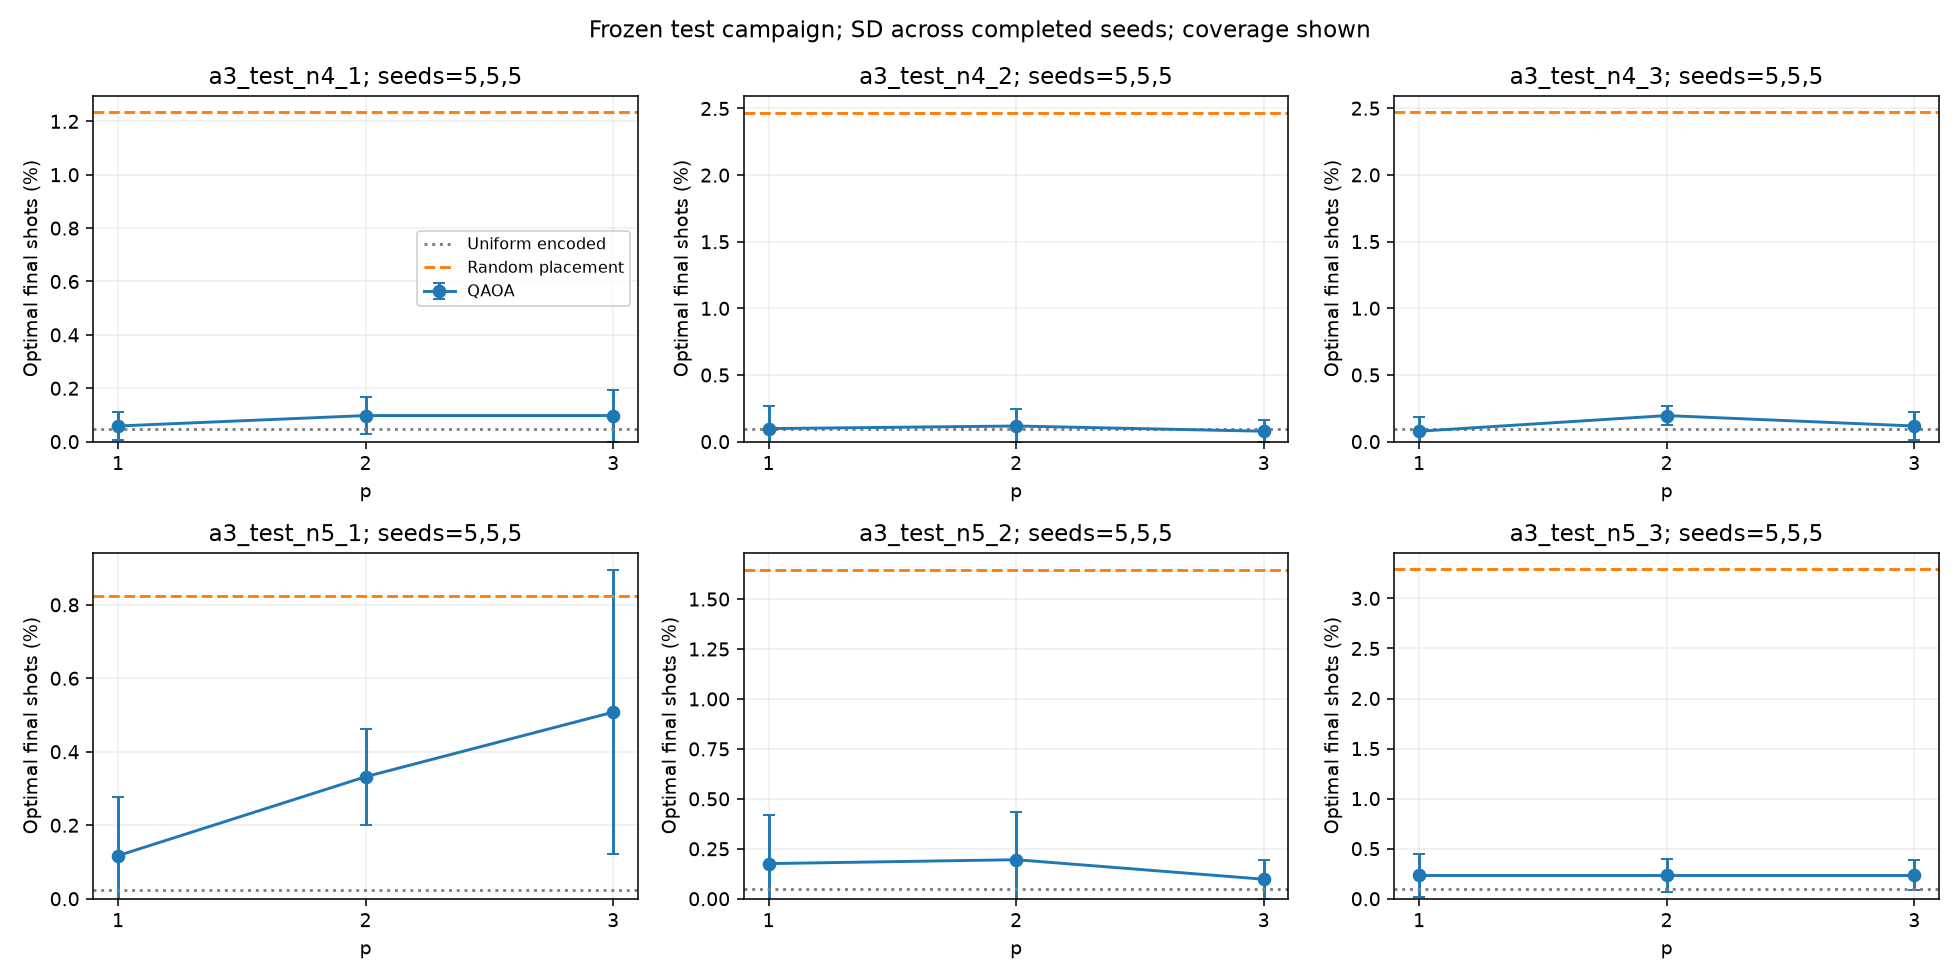

Status: complete
Coverage: {'planned': 90, 'completed': 90, 'status_counts': {'completed': 90}, 'valid_completed_batches': 90, 'optimal_completed_batches': 63}


In [7]:
ROWS, SUMMARY = analyse_test_campaign(FOLDER, CONTEXT)
GROUPS = pd.DataFrame(SUMMARY['groups'])
display(GROUPS[['instance_id','p','planned','completed','valid_batches','optimal_batches',
    'feasible_probability_mean','optimal_probability_mean','optimal_lift_encoded_mean',
    'optimal_lift_structured_random_mean','total_seconds_median']])
from IPython.display import Image
display(Image(filename=str(FOLDER/'test_quality.png')))
print('Status:', SUMMARY['status'])
print('Coverage:', SUMMARY['coverage'])

## Bước8 — Đối chiếu chi phí và giới hạn phép đo

QAOA median chỉ trên completed runs; failure/pending vẫn ở CSV. Classical timing warm-process gồm validation/RNG/check/output, loại import/calibration/reference prep. QAOA trial gồm optimization/final sampling/postprocessing. Đây không phải benchmark end-to-end đồng bộ mọi overhead; không suy quantum advantage từ lift encoded.

In [8]:
CLASSICAL = _read(FOLDER/'classical_timings.json') if (FOLDER/'classical_timings.json').is_file() else []
COST_ROWS = []
for g in SUMMARY['groups']:
    c = {r['method']:r['seconds_median'] for r in CLASSICAL if r['instance_id']==g['instance_id']}
    COST_ROWS.append(dict(instance_id=g['instance_id'],p=g['p'],completed=g['completed'],
        qaoa_seconds_median=g['total_seconds_median'],exact_seconds=c.get('exact_enumeration'),
        random_1024_seconds=c.get('random_assignment'),nfev_median=g['nfev_median'],
        algorithm_shots_median=g['total_algorithm_shots_median']))
display(pd.DataFrame(COST_ROWS))
print('FF/BFD/MILP chưa nằm trong gói A20. Chỉ kết luận trong phạm vi6case test.')

,instance_id,p,completed,qaoa_seconds_median,exact_seconds,random_1024_seconds,nfev_median,algorithm_shots_median
0,a3_test_n4_1,1,5,4.084542,0.000134,0.003168,32,34816
1,a3_test_n4_1,2,5,6.404018,0.000134,0.003168,41,44032
2,a3_test_n4_1,3,5,14.933195,0.000134,0.003168,57,60416
3,a3_test_n4_2,1,5,16.879111,0.000138,0.003221,32,34816
4,a3_test_n4_2,2,5,25.913616,0.000138,0.003221,41,44032
5,a3_test_n4_2,3,5,41.960784,0.000138,0.003221,55,58368
6,a3_test_n4_3,1,5,11.975533,0.000135,0.003188,30,32768
7,a3_test_n4_3,2,5,31.477840,0.000135,0.003188,38,40960
8,a3_test_n4_3,3,5,63.943921,0.000135,0.003188,58,61440
9,a3_test_n5_1,1,5,53.905475,0.000399,0.003562,30,32768


FF/BFD/MILP chưa nằm trong gói A20. Chỉ kết luận trong phạm vi6case test.


## Bước9 — Xuất kết quả đầy đủ hoặc partial

ZIP chứa ledger/budget, context, raw reports, CSV90row, summary, source bytes, controls, classical timing, plot và checksum. Complete chỉ xác nhận đủ90trial completed, không chứng nhận chất lượng. Nếu partial, gửi luôn để đánh giá nguyên nhân và phạm vi thật. Save notebook sau cell này.

In [9]:
ARCHIVE, ROWS, SUMMARY = export_test_campaign(FOLDER, CONTEXT)
print(json.dumps({k:SUMMARY[k] for k in ['status','coverage','budget','halt']},ensure_ascii=False,indent=2))
print('Gửi ZIP:', ARCHIVE)
print('Gửi kèm notebook20 đã Save sau khi chạy.')
print('RESUME_DIR =', repr(FOLDER.relative_to(ROOT).as_posix()))
print('Không thay source/runtime/config hoặc reset budget khi resume.')

{
  "status": "complete",
  "coverage": {
    "planned": 90,
    "completed": 90,
    "status_counts": {
      "completed": 90
    },
    "valid_completed_batches": 90,
    "optimal_completed_batches": 63
  },
  "budget": {
    "limit_seconds": 21600.0,
    "charged_seconds": 12515.768197500001,
    "remaining_seconds": 9084.231802499999,
    "unconfirmed_wall_seconds": 0.0,
    "accounting": "metered active stages plus conservative unclosed-session recovery; idle outside closed stages excluded"
  },
  "halt": null
}
Gửi ZIP: C:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement\data\reference_results\phase4l_three_host_test\test_20261012T112947210418Z\test_20261012T112947210418Z.zip
Gửi kèm notebook20 đã Save sau khi chạy.
RESUME_DIR = 'data/reference_results/phase4l_three_host_test/test_20261012T112947210418Z'
Không thay source/runtime/config hoặc reset budget khi resume.
